# Đánh giá chung B03: K-Means, GMM và DBSCAN

Notebook làm 4 việc: so sánh chỉ số, thử nhiều seed, thử eps của DBSCAN và xem RFM gốc theo cụm.

Đầu vào là **file đã clean của An**: `data/online_retail_clean_zscore.csv`.
Đọc file này để tạo RFM dùng chung cho ba mô hình, không chạy lại bước cleaning.

Mở notebook trong thư mục `06_model_evaluation`, chọn **Restart Kernel → Run All**.
File clean và kết quả Excel ở `data/`; hình ở `figures/` cạnh notebook.

## 1. Import và thông số

In [ ]:
from pathlib import Path
from itertools import combinations
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.preprocessing import PowerTransformer, StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)
from threadpoolctl import threadpool_limits

SEED = 42
SEEDS = [1, 7, 13, 21, 42, 99]
K_GRID = range(2, 11)
EPS_GRID = [0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.4, 0.5, 0.7, 1.0, 1.5, 2.0]
MS_GRID = [4, 6, 8, 10, 15, 20]
COV_GRID = ['full', 'tied', 'diag', 'spherical']
FEATURES = ['Recency', 'Frequency', 'Monetary']

threadpool_limits(limits=1)
pd.set_option('display.max_columns', 20)
pd.set_option('display.width', 180)

## 2. Đọc file clean của An và tạo RFM

In [2]:
df = pd.read_csv('data/online_retail_clean_zscore.csv',
                 dtype={'CustomerID': 'string', 'InvoiceNo': 'string'})
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])
df['Amount'] = df['Quantity'] * df['UnitPrice']

# Ngày sau ngày mua cuối cùng trong file clean.
reference_date = df['InvoiceDate'].max().normalize() + pd.Timedelta(days=1)
rfm = df.groupby('CustomerID').agg(
    LastPurchase=('InvoiceDate', 'max'),
    Frequency=('InvoiceNo', 'nunique'),
    Monetary=('Amount', 'sum'))
rfm['Recency'] = (reference_date - rfm['LastPurchase'].dt.normalize()).dt.days
rfm = rfm.reset_index()[['CustomerID'] + FEATURES]
X = rfm[FEATURES].copy()
assert rfm['CustomerID'].notna().all() and rfm['CustomerID'].is_unique
assert np.isfinite(X.to_numpy()).all() and (X >= 0).all().all()
assert np.isclose(X['Monetary'].sum(), df['Amount'].sum())
OUT = Path('data')
FIG = Path('figures')
FIG.mkdir(exist_ok=True)
print('Số dòng clean:', len(df), '| Số khách:', len(rfm))
print('Ngày tham chiếu:', reference_date.date())
display(rfm.head())

Số dòng clean: 523577 | Số khách: 4323
Ngày tham chiếu: 2011-12-10


,CustomerID,Recency,Frequency,Monetary
0,12347.0,3,7,4310.00
1,12348.0,76,5,3150.16
2,12349.0,19,1,1457.55
3,12350.0,311,1,334.40
4,12352.0,37,8,3244.95


R = số ngày lịch từ lần mua cuối đến 10/12/2011. F = số hóa đơn mua khác nhau.
M = tổng Quantity × UnitPrice trong file clean (GBP).
CustomerID chỉ dùng để ghép kết quả, không đưa vào mô hình.

## 3. Tiền xử lý B03 — chỉ fit một lần cho cả ba mô hình

In [3]:
power = PowerTransformer(method='yeo-johnson', standardize=False)
scaler = StandardScaler()
pca = PCA(n_components=0.90, svd_solver='full')
Z = pca.fit_transform(scaler.fit_transform(power.fit_transform(X)))
assert np.isfinite(Z).all()
print('Đầu vào mô hình:', Z.shape)
print('Phương sai PCA giữ lại:', round(pca.explained_variance_ratio_.sum(), 4))
display(pd.DataFrame({'Feature': FEATURES, 'Lambda': power.lambdas_}).round(4))

Đầu vào mô hình: (4323, 2)
Phương sai PCA giữ lại: 0.9363


,Feature,Lambda
0,Recency,0.1253
1,Frequency,-0.7072
2,Monetary,-0.0712


## 4. Khảo sát và chọn tham số

K-Means chọn Silhouette cao nhất trong k=2…10, n_init=20.
GMM chọn BIC thấp nhất trong k=2…10 và 4 loại covariance, n_init=10; phải hội tụ và cụm nhỏ nhất ≥1% số khách.
DBSCAN chọn Silhouette không nhiễu cao nhất trong lưới, với ít nhất 2 cụm và nhiễu ≤5%.
Nếu không có cấu hình đạt điều kiện thì ghi nhận, không tự nới điều kiện.

In [4]:
km_rows = []
for k in K_GRID:
    model = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(Z)
    km_rows.append({'k': k, 'Silhouette': silhouette_score(Z, model.labels_),
                    'Inertia': model.inertia_,
                    'Min_cluster': int(np.bincount(model.labels_).min())})
km_grid = pd.DataFrame(km_rows)
km_k = int(km_grid.loc[km_grid['Silhouette'].idxmax(), 'k'])
km = KMeans(n_clusters=km_k, n_init=20, random_state=SEED).fit(Z)
display(km_grid.round(4))
print('K-Means chọn k =', km_k)

K-Means chọn k = 2


,k,Silhouette,Inertia,Min_cluster
0,2,0.4656,5321.2830,1959
1,3,0.3684,3882.2530,1093
2,4,0.3858,2864.4267,926
3,5,0.3820,2289.3580,800
4,6,0.3825,1886.4253,629
5,7,0.3710,1662.7212,381
6,8,0.3663,1493.3258,296
7,9,0.3575,1344.1398,277
8,10,0.3565,1216.9614,297


In [5]:
gm_rows = []
for cov in COV_GRID:
    for k in K_GRID:
        model = GaussianMixture(n_components=k, covariance_type=cov, n_init=10,
                                max_iter=300, random_state=SEED).fit(Z)
        labels = model.predict(Z)
        gm_rows.append({'k': k, 'Covariance': cov, 'BIC': model.bic(Z),
                        'Converged': model.converged_,
                        'Min_cluster': int(np.bincount(labels, minlength=k).min())})
gm_grid = pd.DataFrame(gm_rows)
gm_valid = gm_grid[gm_grid['Converged'] & (gm_grid['Min_cluster'] >= 0.01 * len(X))]
if gm_valid.empty:
    raise ValueError('GMM không có cấu hình đạt điều kiện; kiểm tra bảng gm_grid.')
gm_best = gm_valid.loc[gm_valid['BIC'].idxmin()]
gm_k, gm_cov = int(gm_best['k']), gm_best['Covariance']
gm = GaussianMixture(n_components=gm_k, covariance_type=gm_cov, n_init=10,
                     max_iter=300, random_state=SEED).fit(Z)
assert gm.converged_
display(gm_grid.sort_values('BIC').head(10).round(4))
print('GMM chọn:', gm_k, 'cụm, covariance =', gm_cov)

GMM chọn: 4 cụm, covariance = full


,k,Covariance,BIC,Converged,Min_cluster
2,4,full,24767.3513,True,767
3,5,full,24795.7734,True,688
4,6,full,24807.5133,True,652
34,9,spherical,24831.3252,True,154
5,7,full,24832.2290,True,437
35,10,spherical,24833.7891,True,166
6,8,full,24842.3865,True,319
33,8,spherical,24847.1201,True,308
7,9,full,24856.7301,True,274
24,8,diag,24859.0402,True,266


In [6]:
db_rows = []
for ms in MS_GRID:
    for eps in EPS_GRID:
        labels = DBSCAN(eps=eps, min_samples=ms).fit_predict(Z)
        mask = labels != -1
        k = len(np.unique(labels[mask]))
        noise = 100 * (~mask).mean()
        sil = np.nan
        if 2 <= k < mask.sum() and noise <= 5:
            sil = silhouette_score(Z[mask], labels[mask])
        db_rows.append({'eps': eps, 'min_samples': ms, 'Clusters': k,
                        'Noise_pct': noise, 'Silhouette_non_noise': sil})
db_grid = pd.DataFrame(db_rows)
db_valid = db_grid[db_grid['Silhouette_non_noise'].notna()]
db = None
if db_valid.empty:
    print('DBSCAN không có cấu hình đạt điều kiện. Không chọn model.')
else:
    db_best = db_valid.loc[db_valid['Silhouette_non_noise'].idxmax()]
    db = DBSCAN(eps=float(db_best['eps']), min_samples=int(db_best['min_samples'])).fit(Z)
    display(db_valid.sort_values('Silhouette_non_noise', ascending=False).head(10).round(4))

,eps,min_samples,Clusters,Noise_pct,Silhouette_non_noise
16,0.25,6,2,1.1797,0.4315
27,0.20,8,2,2.9609,0.3065
3,0.20,4,3,1.4805,0.1971
39,0.20,10,2,3.7474,0.1036
15,0.20,6,3,1.7812,0.0772
14,0.15,6,3,4.3488,0.0729
4,0.25,4,4,0.6940,-0.0055
2,0.15,4,8,2.5677,-0.2561


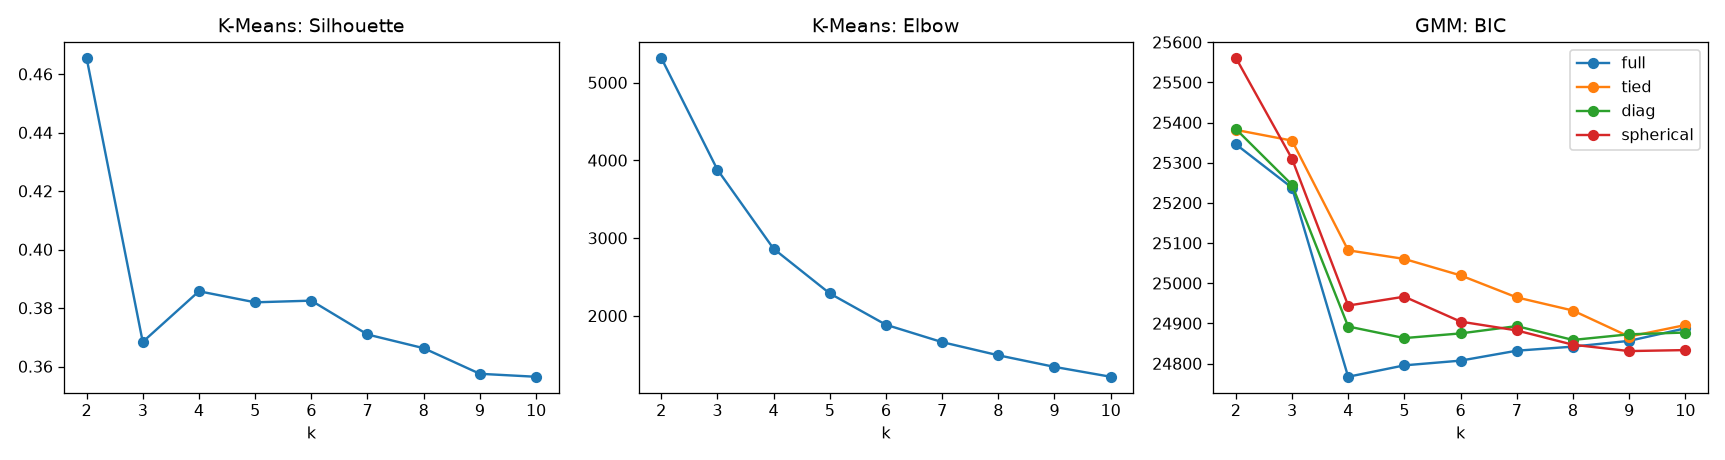

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(km_grid['k'], km_grid['Silhouette'], 'o-')
axes[0].set_title('K-Means: Silhouette')
axes[1].plot(km_grid['k'], km_grid['Inertia'], 'o-')
axes[1].set_title('K-Means: Elbow')
for cov in COV_GRID:
    part = gm_grid[gm_grid['Covariance'] == cov]
    axes[2].plot(part['k'], part['BIC'], 'o-', label=cov)
axes[2].set_title('GMM: BIC'); axes[2].legend()
for ax in axes: ax.set_xlabel('k')
fig.tight_layout(); fig.savefig(FIG / 'chon_tham_so.png', dpi=140)
plt.show()

## 5. Bảng so sánh và hình phân cụm

Silhouette và CHI cao hơn, DBI thấp hơn là tốt hơn theo tiêu chí tương ứng.
DBSCAN bỏ nhãn -1 khi tính chỉ số, nên bảng đầu **khác tập đánh giá**.
Bảng thứ hai tính lại cả ba mô hình trên cùng các khách không nhiễu của DBSCAN.
Các chỉ số này là đánh giá nội bộ trên cùng cửa sổ lịch sử, chưa phải kiểm định dự báo tương lai.

In [8]:
labels_by_model = {'K-Means': km.labels_, 'GMM': gm.predict(Z)}
if db is not None: labels_by_model['DBSCAN'] = db.labels_

def score(name, labels, keep):
    part = labels[keep]
    k = len(np.unique(part))
    result = {'Model': name, 'Customers_evaluated': int(keep.sum()), 'Clusters': k,
              'Coverage_pct': 100 * keep.mean(),
              'Silhouette': np.nan, 'DBI': np.nan, 'CHI': np.nan}
    if 2 <= k < len(part):
        result.update(Silhouette=silhouette_score(Z[keep], part),
                      DBI=davies_bouldin_score(Z[keep], part),
                      CHI=calinski_harabasz_score(Z[keep], part))
    return result

comparison = pd.DataFrame([score(name, labels, labels != -1)
                           for name, labels in labels_by_model.items()])
comparison['Noise_pct'] = [100 * (labels == -1).mean() for labels in labels_by_model.values()]
common_comparison = pd.DataFrame()
if db is not None:
    common = db.labels_ != -1
    common_comparison = pd.DataFrame([score(name, labels, common)
                                     for name, labels in labels_by_model.items()])
display(comparison.round(4))
print('Cùng tập khách không nhiễu DBSCAN:')
display(common_comparison.round(4))

Cùng tập khách không nhiễu DBSCAN:


,Model,Customers_evaluated,Clusters,Coverage_pct,Silhouette,DBI,CHI,Noise_pct
0,K-Means,4323,2,100.0000,0.4656,0.7978,5539.7624,0.0000
1,GMM,4323,4,100.0000,0.3588,0.8793,4107.8274,0.0000
2,DBSCAN,4272,2,98.8203,0.4315,0.4155,43.1200,1.1797


,Model,Customers_evaluated,Clusters,Coverage_pct,Silhouette,DBI,CHI
0,K-Means,4272,2,98.8203,0.4673,0.7960,5561.4869
1,GMM,4272,4,98.8203,0.3660,0.8725,4256.6614
2,DBSCAN,4272,2,98.8203,0.4315,0.4155,43.1200


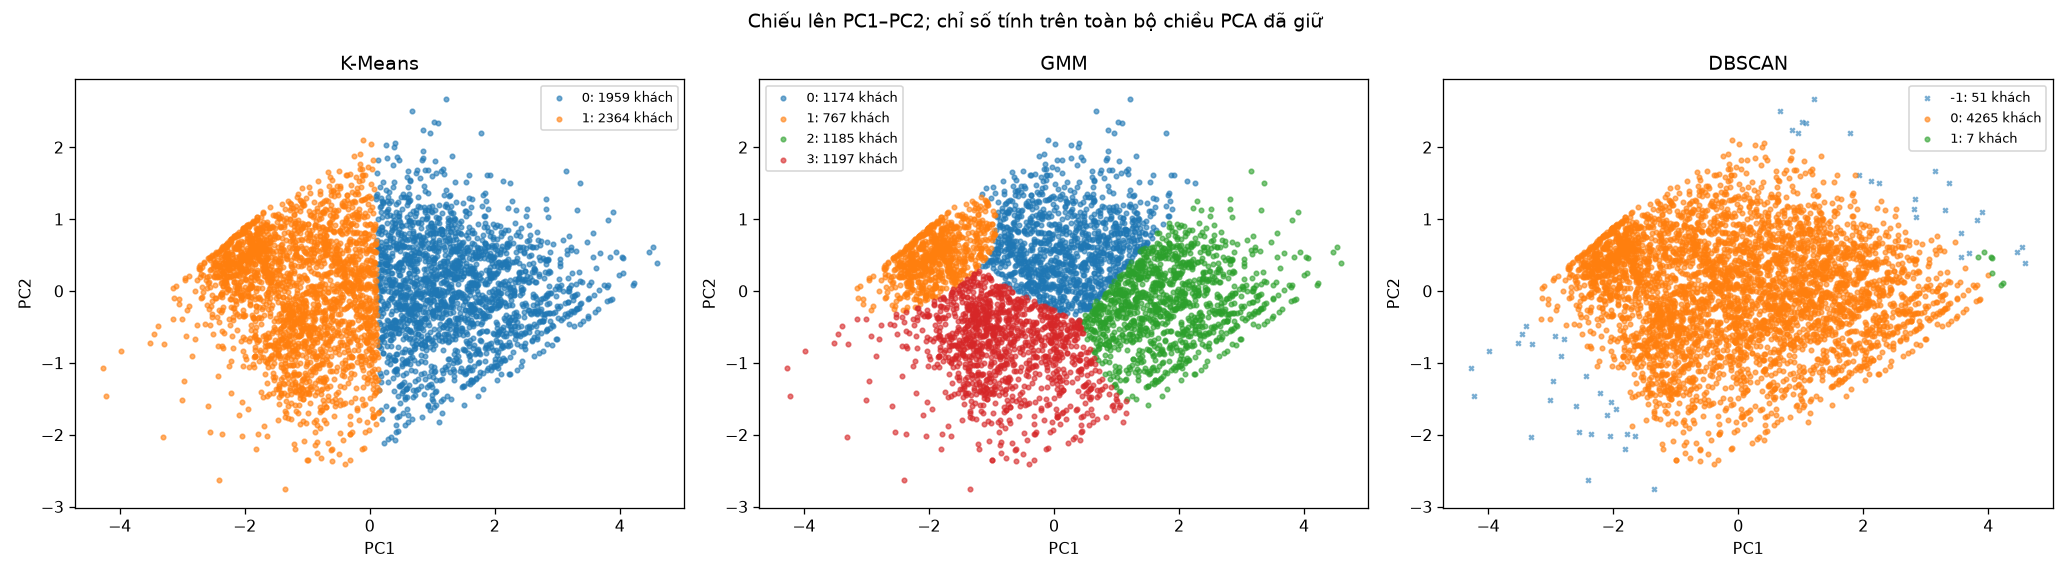

In [9]:
fig, axes = plt.subplots(1, len(labels_by_model), figsize=(6 * len(labels_by_model), 5), squeeze=False)
for ax, (name, labels) in zip(axes[0], labels_by_model.items()):
    for cluster in sorted(np.unique(labels)):
        mask = labels == cluster
        ax.scatter(Z[mask, 0], Z[mask, 1] if Z.shape[1] > 1 else np.zeros(mask.sum()),
                   s=8, alpha=0.6, marker='x' if cluster == -1 else 'o',
                   label=f'{cluster}: {mask.sum()} khách')
    ax.set_title(name); ax.set_xlabel('PC1'); ax.set_ylabel('PC2')
    ax.legend(fontsize=8)
fig.suptitle('Chiếu lên PC1–PC2; chỉ số tính trên toàn bộ chiều PCA đã giữ')
fig.tight_layout(); fig.savefig(FIG / 'so_sanh_3_mo_hinh.png', dpi=140)
plt.show()

## 6. Độ ổn định khi thay seed

Giữ nguyên RFM, ma trận Z, k và các tham số đã chọn. Chỉ đổi seed của K-Means/GMM.
ARI được tính giữa **mọi cặp seed**, không chỉ so với seed 42.
ARI gần 1 nghĩa là cách chia giống nhau; không chứng minh cụm có ý nghĩa kinh doanh.
Đây là ổn định do khởi tạo, chưa kiểm tra lấy mẫu lại khách hàng.

In [10]:
seed_labels = {}
seed_rows = []
for seed in SEEDS:
    models = {
        'K-Means': KMeans(n_clusters=km_k, n_init=20, random_state=seed),
        'GMM': GaussianMixture(n_components=gm_k, covariance_type=gm_cov,
                               n_init=10, max_iter=300, random_state=seed)}
    for name, model in models.items():
        labels = model.fit_predict(Z)
        seed_labels[name, seed] = labels
        row = score(name, labels, np.ones(len(X), dtype=bool))
        row.update(Seed=seed, Converged=bool(model.converged_) if name == 'GMM' else True)
        seed_rows.append(row)
seed_results = pd.DataFrame(seed_rows)
pair_rows = []
for name in ['K-Means', 'GMM']:
    for seed1, seed2 in combinations(SEEDS, 2):
        pair_rows.append({'Model': name, 'Seed_1': seed1, 'Seed_2': seed2,
                         'ARI': adjusted_rand_score(seed_labels[name, seed1], seed_labels[name, seed2])})
pairs = pd.DataFrame(pair_rows)
stability = pairs.groupby('Model')['ARI'].agg(ARI_mean='mean', ARI_min='min', Pairs='count').reset_index()
stability['All_converged'] = stability['Model'].map(seed_results.groupby('Model')['Converged'].all())
assert (stability['Pairs'] == len(SEEDS) * (len(SEEDS) - 1) // 2).all()
display(stability.round(4))
display(seed_results.round(4))

,Model,ARI_mean,ARI_min,Pairs,All_converged
0,GMM,0.9840,0.9682,15,True
1,K-Means,0.9971,0.9935,15,True


,Model,Customers_evaluated,Clusters,Coverage_pct,Silhouette,DBI,CHI,Seed,Converged
0,K-Means,4323,2,100.0,0.4657,0.7977,5539.7560,1,True
1,GMM,4323,4,100.0,0.3599,0.8766,4128.7085,1,True
2,K-Means,4323,2,100.0,0.4657,0.7977,5539.7293,7,True
3,GMM,4323,4,100.0,0.3599,0.8789,4115.0747,7,True
4,K-Means,4323,2,100.0,0.4657,0.7977,5539.7560,13,True
5,GMM,4323,4,100.0,0.3602,0.8787,4117.6967,13,True
6,K-Means,4323,2,100.0,0.4656,0.7979,5539.7475,21,True
7,GMM,4323,4,100.0,0.3593,0.8785,4108.7566,21,True
8,K-Means,4323,2,100.0,0.4656,0.7978,5539.7624,42,True
9,GMM,4323,4,100.0,0.3588,0.8793,4107.8274,42,True


## 7. DBSCAN nhạy với eps ra sao?

Giữ min_samples, thử eps ở mức −10%, −5%, gốc, +5%, +10%.
ARI tính cả nhãn nhiễu, có thể cao khi một cụm quá lớn; đọc cùng số cụm, tỷ lệ nhiễu,
tỷ trọng cụm lớn nhất và số khách đổi trạng thái nhiễu. Không gọi bước này là thử seed.

In [11]:
sensitivity_rows = []
if db is not None:
    for factor in [0.90, 0.95, 1.0, 1.05, 1.10]:
        eps = float(db.eps * factor)
        labels = DBSCAN(eps=eps, min_samples=db.min_samples).fit_predict(Z)
        sizes = pd.Series(labels[labels != -1]).value_counts()
        sensitivity_rows.append({
            'eps': eps, 'min_samples': db.min_samples, 'Clusters': len(sizes),
            'Noise_pct': 100 * (labels == -1).mean(),
            'Largest_cluster_pct': 100 * sizes.max() / len(X) if len(sizes) else 0,
            'ARI_vs_selected': adjusted_rand_score(db.labels_, labels),
            'Noise_status_changed': int(((labels == -1) != (db.labels_ == -1)).sum())})
else:
    print('Không thử eps vì chưa có DBSCAN đạt điều kiện.')
sensitivity = pd.DataFrame(sensitivity_rows)
display(sensitivity.round(4))

,eps,min_samples,Clusters,Noise_pct,Largest_cluster_pct,ARI_vs_selected,Noise_status_changed
0,0.2250,6,1,1.5498,98.4502,0.9243,16
1,0.2375,6,2,1.3185,98.5195,0.9489,6
2,0.2500,6,2,1.1797,98.6583,1.0000,0
3,0.2625,6,2,1.0409,98.9128,0.8922,6
4,0.2750,6,1,0.9947,99.0053,0.8475,8


## 8. Hồ sơ cụm trên RFM gốc

Trung vị tính trước Yeo–Johnson, scale và PCA. % Monetary dùng **tổng M** của cụm chia tổng M của tất cả khách,
bao gồm cả nhóm nhiễu khi có. Nhãn cụm 0/1/... chỉ là mã; −1 là nhiễu, không tự xem là nhóm VIP.

In [12]:
profile_tables = []
assignments = rfm.copy()
for name, labels in labels_by_model.items():
    assignments[name] = labels
    profile = X.assign(Cluster=labels).groupby('Cluster').agg(
        Customers=('Monetary', 'size'), Median_R=('Recency', 'median'),
        Median_F=('Frequency', 'median'), Median_M=('Monetary', 'median'),
        Total_M=('Monetary', 'sum')).reset_index()
    profile.insert(0, 'Model', name)
    profile['Customer_pct'] = 100 * profile['Customers'] / len(X)
    profile['Monetary_pct'] = 100 * profile['Total_M'] / X['Monetary'].sum()
    assert profile['Customers'].sum() == len(X)
    assert np.isclose(profile['Monetary_pct'].sum(), 100)
    profile_tables.append(profile)
    print(name)
    display(profile.round(2))
profiles = pd.concat(profile_tables, ignore_index=True)

K-Means
GMM
DBSCAN


,Model,Cluster,Customers,Median_R,Median_F,Median_M,Total_M,Customer_pct,Monetary_pct
0,K-Means,0,1959,20.0,5.0,2045.53,8490626.71,45.32,88.93
1,K-Means,1,2364,113.0,1.0,327.84,1056433.93,54.68,11.07


,Model,Cluster,Customers,Median_R,Median_F,Median_M,Total_M,Customer_pct,Monetary_pct
0,GMM,0,1174,81.0,3.0,1121.14,2017268.66,27.16,21.13
1,GMM,1,767,262.0,1.0,243.76,227008.63,17.74,2.38
2,GMM,2,1185,12.0,7.0,2665.62,6867843.30,27.41,71.94
3,GMM,3,1197,38.0,1.0,309.05,434940.05,27.69,4.56


,Model,Cluster,Customers,Median_R,Median_F,Median_M,Total_M,Customer_pct,Monetary_pct
0,DBSCAN,-1,51,52.0,1.0,45.60,1473897.87,1.18,15.44
1,DBSCAN,0,4265,51.0,2.0,696.89,7619792.76,98.66,79.81
2,DBSCAN,1,7,3.0,96.0,64617.02,453370.01,0.16,4.75


## 9. Đọc kết quả để trình bày

- Đọc bảng chọn k cùng Elbow, bảng so sánh, ổn định và hồ sơ cụm. Không chỉ lấy chỉ số cao nhất.
- Nếu K-Means ổn định và hai nhóm RFM dễ giải thích thì có thể chọn làm mô hình chính.
- GMM giúp xem các nhóm nhỏ hơn; xem thêm xác suất và chồng lấn nếu muốn diễn giải sâu.
- Nếu DBSCAN gom gần hết khách vào một cụm, dùng nó như kết quả đối chứng về hạn chế phân khúc.


In [13]:
km_info = comparison.set_index('Model').loc['K-Means']
print(f"K-Means: {int(km_info['Clusters'])} cụm, Silhouette = {km_info['Silhouette']:.4f}, DBI = {km_info['DBI']:.4f}")
for _, row in stability.iterrows():
    print(f"{row['Model']}: ARI trung bình = {row['ARI_mean']:.4f}, thấp nhất = {row['ARI_min']:.4f}")
for _, row in profiles[profiles['Model'] == 'K-Means'].iterrows():
    print(f"Cụm {int(row['Cluster'])}: {int(row['Customers'])} khách ({row['Customer_pct']:.1f}%), "
          f"R/F/M trung vị = {row['Median_R']:.0f}/{row['Median_F']:.0f}/{row['Median_M']:.2f}, "
          f"chiếm {row['Monetary_pct']:.1f}% tổng Monetary")
if not sensitivity.empty:
    print('DBSCAN còn ít nhất 2 cụm ở', int((sensitivity['Clusters'] >= 2).sum()),
          '/', len(sensitivity), 'mức eps đã thử.')

K-Means: 2 cụm, Silhouette = 0.4656, DBI = 0.7978
GMM: ARI trung bình = 0.9840, thấp nhất = 0.9682
K-Means: ARI trung bình = 0.9971, thấp nhất = 0.9935
Cụm 0: 1959 khách (45.3%), R/F/M trung vị = 20/5/2045.53, chiếm 88.9% tổng Monetary
Cụm 1: 2364 khách (54.7%), R/F/M trung vị = 113/1/327.84, chiếm 11.1% tổng Monetary
DBSCAN còn ít nhất 2 cụm ở 3 / 5 mức eps đã thử.
